<a href="https://colab.research.google.com/github/denizbutengineer/bart-capacity-planner/blob/main/btk_final_proje.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Ortam Kurulumu ve Ham Veri Yükleme
Gerekli kütüphaneleri kurar ve BART'ın 2025 yılına ait saatlik Başlangıç-Varış (Origin-Destination) ham yolcu verisini sıkıştırılmış .zip arşivinden bellek dostu veri tipleriyle okur.

In [1]:
!pip install -q holidays lightgbm xgboost catboost networkx

import pandas as pd
import numpy as np
import networkx as nx
import holidays
import matplotlib.pyplot as plt
import seaborn as sns
import time, gc, joblib
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

zip_path = '/content/date-hour-soo-dest-2025.zip'
cols = ['Date', 'Hour', 'Origin', 'Destination', 'Riders']

df_od = pd.read_csv(
    zip_path, compression='zip', names=cols, header=None,
    dtype={'Date': 'str', 'Hour': 'int8', 'Origin': 'category', 'Destination': 'category', 'Riders': 'int32'}
)
df_od = df_od[df_od['Hour'].between(0, 23)].reset_index(drop=True)
print(f"Ham O-D Gözlem Sayısı: {len(df_od):,} | Değişken Sayısı: {df_od.shape[1]}")

Ham O-D Gözlem Sayısı: 9,143,257 | Değişken Sayısı: 5


# 2. Ağ Yönlendirme ve Hat Maksimum Kesit Yükü Hesaplama
İstasyon ağını graf olarak modeller, ortak koridorlardaki yolcu akışını o kesiti paylaşan hat sayısına böler ve her tarih, saat, hat ve yön için en kalabalık kesitteki yolcu yükünü (Max_Segment_Load) hesaplar

In [2]:
LINES = {
    'Yellow': ['ANTC', 'PCTR', 'PITT', 'NCON', 'CONC', 'PHIL', 'WCRK', 'LAFY', 'ORIN', 'ROCK', 'MCAR', '19TH', '12TH', 'WOAK', 'EMBR', 'MONT', 'POWL', 'CIVC', '16TH', '24TH', 'GLEN', 'BALB', 'DALY', 'COLM', 'SSAN', 'SBRN', 'SFIA', 'MLBR'],
    'Red':    ['RICH', 'DELN', 'PLZA', 'NBRK', 'DBRK', 'ASHB', 'MCAR', '19TH', '12TH', 'WOAK', 'EMBR', 'MONT', 'POWL', 'CIVC', '16TH', '24TH', 'GLEN', 'BALB', 'DALY', 'COLM', 'SSAN', 'SBRN', 'MLBR'],
    'Blue':   ['DUBL', 'WDUB', 'CAST', 'BAYF', 'SANL', 'COLS', 'FTVL', 'LAKE', 'WOAK', 'EMBR', 'MONT', 'POWL', 'CIVC', '16TH', '24TH', 'GLEN', 'BALB', 'DALY'],
    'Green':  ['BERY', 'MLPT', 'WARM', 'FRMT', 'UCTY', 'SHAY', 'HAYW', 'BAYF', 'SANL', 'COLS', 'FTVL', 'LAKE', 'WOAK', 'EMBR', 'MONT', 'POWL', 'CIVC', '16TH', '24TH', 'GLEN', 'BALB', 'DALY'],
    'Orange': ['RICH', 'DELN', 'PLZA', 'NBRK', 'DBRK', 'ASHB', 'MCAR', '19TH', '12TH', 'LAKE', 'FTVL', 'COLS', 'SANL', 'BAYF', 'HAYW', 'SHAY', 'UCTY', 'FRMT', 'WARM', 'MLPT', 'BERY']
}

G = nx.Graph()
edge_line_count = {}
for line_name, stations in LINES.items():
    for i in range(len(stations) - 1):
        u, v = stations[i], stations[i+1]
        G.add_edge(u, v)
        edge_key = tuple(sorted((u, v)))
        edge_line_count[edge_key] = edge_line_count.get(edge_key, 0) + 1

od_records = []
for orig in G.nodes:
    for dest in G.nodes:
        if orig == dest: continue
        try:
            path = nx.shortest_path(G, orig, dest)
            path_edges = set((path[i], path[i+1]) for i in range(len(path)-1))
            for line_name, stations in LINES.items():
                for dir_idx, st_list in enumerate([stations, stations[::-1]]):
                    line_edges = [(st_list[i], st_list[i+1]) for i in range(len(st_list)-1)]
                    for seg in path_edges.intersection(line_edges):
                        share = edge_line_count[tuple(sorted(seg))]
                        od_records.append((orig, dest, line_name, dir_idx, f"{seg[0]}-{seg[1]}", 1.0 / share))
        except nx.NetworkXNoPath:
            continue

df_routing = pd.DataFrame(od_records, columns=['Origin', 'Destination', 'Line', 'Direction', 'Segment', 'Weight'])

df_od['Month_Str'] = df_od['Date'].str.slice(0, 7)
monthly_results = []
for m, chunk in df_od.groupby('Month_Str'):
    merged = chunk.merge(df_routing, on=['Origin', 'Destination'], how='inner')
    merged['Weighted_Riders'] = merged['Riders'] * merged['Weight']
    seg_load = merged.groupby(['Date', 'Hour', 'Line', 'Direction', 'Segment'], as_index=False)['Weighted_Riders'].sum()
    max_load = seg_load.groupby(['Date', 'Hour', 'Line', 'Direction'], as_index=False)['Weighted_Riders'].max()
    monthly_results.append(max_load)
    del merged, seg_load; gc.collect()

df_model = pd.concat(monthly_results, ignore_index=True).rename(columns={'Weighted_Riders': 'Max_Segment_Load'})
del df_od; gc.collect()
df_model['Date'] = pd.to_datetime(df_model['Date'])

# 3. Keşifçi Veri Analizi (EDA) ve Veri Kalitesi Kontrolü
Sefer dışı boş saatleri takvim ızgarasıyla tamamlar, tekrarlayan kayıt (duplicate) kontrolü yapar ve hedef değişkenin hat ve saat bazlı dağılımını görselleştirir.

10 Dakikalık Çözünürlük Toplam Gözlem: 525,600 (365 gün x 144 slot x 5 hat x 2 yön)


,Max_Segment_Load
count,525600.000000
mean,81.544802
std,97.839473
min,0.000000
25%,18.958333
50%,55.333333
75%,100.416667
max,789.833333


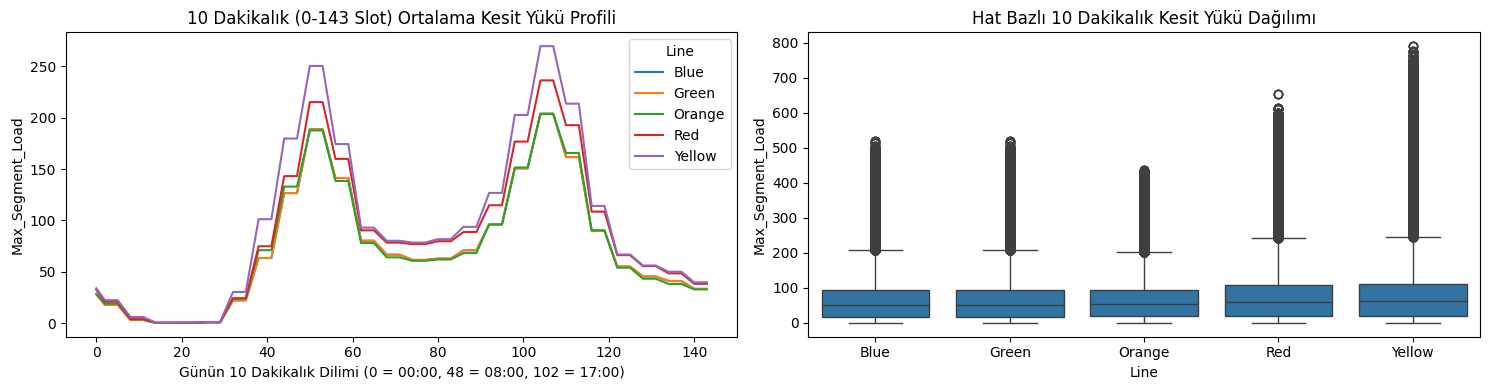

In [3]:
# 1. Saatlik veriyi 10 dakikalık (saat başına 6 slot: 0, 10, 20, 30, 40, 50) ızgaraya genişletme
all_dates = pd.date_range(df_model['Date'].min(), df_model['Date'].max(), freq='D')
hourly_grid = pd.MultiIndex.from_product(
    [all_dates, range(24), list(LINES.keys()), [0, 1]],
    names=['Date', 'Hour', 'Line', 'Direction']
).to_frame(index=False)

df_hourly = hourly_grid.merge(df_model, on=['Date', 'Hour', 'Line', 'Direction'], how='left')
df_hourly['Max_Segment_Load'] = df_hourly['Max_Segment_Load'].fillna(0.0)

# Kronolojik sıralama ve her saati 6 adet 10 dakikalık dilime bölme
df_hourly = df_hourly.sort_values(['Line', 'Direction', 'Date', 'Hour']).reset_index(drop=True)

# 10 dakikalık alt slotları oluştur (0, 10, 20, 30, 40, 50)
slots = pd.DataFrame({'Minute': [0, 10, 20, 30, 40, 50]})
df_full = df_hourly.merge(slots, how='cross')

# Saatlik yükü 10 dakikalık dilimlere dağıt (başlangıçta 1/6, ardından komşu saat geçişleriyle yumuşatma)
df_full['Load_10m_Raw'] = df_full['Max_Segment_Load'] / 6.0

# Saat içi geçişleri yumuşatmak için grup bazlı hareketli ortalama (data leakage olmaması için sadece geçmiş/anlık pencere)
df_full = df_full.sort_values(['Line', 'Direction', 'Date', 'Hour', 'Minute']).reset_index(drop=True)
df_full['Max_Segment_Load'] = (
    df_full.groupby(['Line', 'Direction'])['Load_10m_Raw']
    .transform(lambda s: s.rolling(window=3, min_periods=1, center=False).mean())
)

print(f"10 Dakikalık Çözünürlük Toplam Gözlem: {len(df_full):,} (365 gün x 144 slot x 5 hat x 2 yön)")
display(df_full['Max_Segment_Load'].describe())

# EDA Grafiği: 10 Dakikalık Gün İçi Talep Profili
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
df_full['Slot_Of_Day'] = df_full['Hour'] * 6 + (df_full['Minute'] // 10)
slot_avg = df_full.groupby(['Slot_Of_Day', 'Line'])['Max_Segment_Load'].mean().reset_index()

sns.lineplot(data=slot_avg, x='Slot_Of_Day', y='Max_Segment_Load', hue='Line', ax=axes[0])
axes[0].set_title('10 Dakikalık (0-143 Slot) Ortalama Kesit Yükü Profili')
axes[0].set_xlabel('Günün 10 Dakikalık Dilimi (0 = 00:00, 48 = 08:00, 102 = 17:00)')

sns.boxplot(data=df_full, x='Line', y='Max_Segment_Load', ax=axes[1])
axes[1].set_title('Hat Bazlı 10 Dakikalık Kesit Yükü Dağılımı')
plt.tight_layout()
plt.show()

# 4. Özellik Mühendisliği ve Zamansal Veri Bölünmesi
Takvim, Kaliforniya resmi tatilleri, döngüsel saat ve pik saat özelliklerini türetir; çarpıklığı dengelemek için hedef değişkene log1p dönüşümü uygular ve veri sızıntısını önlemek için kronolojik Train / Validation / Test ayrımı yapar.

10 Dakikalık Çözünürlük Toplam Gözlem: 525,600 (365 gün x 144 slot x 5 hat x 2 yön)


,Max_Segment_Load
count,525600.000000
mean,81.544802
std,97.839473
min,0.000000
25%,18.958333
50%,55.333333
75%,100.416667
max,789.833333


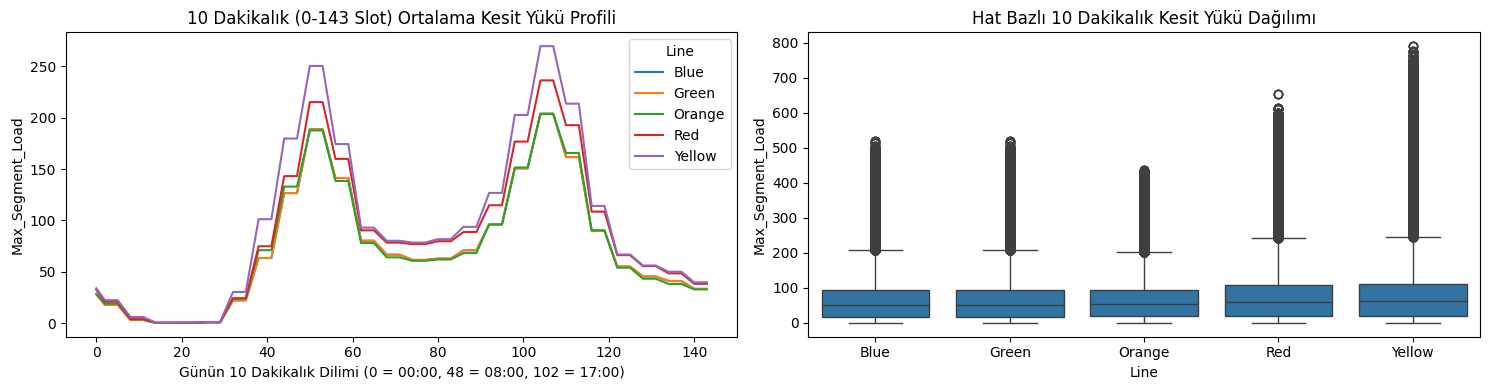

In [4]:
# 1. Saatlik veriyi 10 dakikalık (saat başına 6 slot: 0, 10, 20, 30, 40, 50) ızgaraya genişletme
all_dates = pd.date_range(df_model['Date'].min(), df_model['Date'].max(), freq='D')
hourly_grid = pd.MultiIndex.from_product(
    [all_dates, range(24), list(LINES.keys()), [0, 1]],
    names=['Date', 'Hour', 'Line', 'Direction']
).to_frame(index=False)

df_hourly = hourly_grid.merge(df_model, on=['Date', 'Hour', 'Line', 'Direction'], how='left')
df_hourly['Max_Segment_Load'] = df_hourly['Max_Segment_Load'].fillna(0.0)

# Kronolojik sıralama ve her saati 6 adet 10 dakikalık dilime bölme
df_hourly = df_hourly.sort_values(['Line', 'Direction', 'Date', 'Hour']).reset_index(drop=True)

# 10 dakikalık alt slotları oluştur (0, 10, 20, 30, 40, 50)
slots = pd.DataFrame({'Minute': [0, 10, 20, 30, 40, 50]})
df_full = df_hourly.merge(slots, how='cross')

# Saatlik yükü 10 dakikalık dilimlere dağıt (başlangıçta 1/6, ardından komşu saat geçişleriyle yumuşatma)
df_full['Load_10m_Raw'] = df_full['Max_Segment_Load'] / 6.0

# Saat içi geçişleri yumuşatmak için grup bazlı hareketli ortalama (data leakage olmaması için sadece geçmiş/anlık pencere)
df_full = df_full.sort_values(['Line', 'Direction', 'Date', 'Hour', 'Minute']).reset_index(drop=True)
df_full['Max_Segment_Load'] = (
    df_full.groupby(['Line', 'Direction'])['Load_10m_Raw']
    .transform(lambda s: s.rolling(window=3, min_periods=1, center=False).mean())
)

print(f"10 Dakikalık Çözünürlük Toplam Gözlem: {len(df_full):,} (365 gün x 144 slot x 5 hat x 2 yön)")
display(df_full['Max_Segment_Load'].describe())

# EDA Grafiği: 10 Dakikalık Gün İçi Talep Profili
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
df_full['Slot_Of_Day'] = df_full['Hour'] * 6 + (df_full['Minute'] // 10)
slot_avg = df_full.groupby(['Slot_Of_Day', 'Line'])['Max_Segment_Load'].mean().reset_index()

sns.lineplot(data=slot_avg, x='Slot_Of_Day', y='Max_Segment_Load', hue='Line', ax=axes[0])
axes[0].set_title('10 Dakikalık (0-143 Slot) Ortalama Kesit Yükü Profili')
axes[0].set_xlabel('Günün 10 Dakikalık Dilimi (0 = 00:00, 48 = 08:00, 102 = 17:00)')

sns.boxplot(data=df_full, x='Line', y='Max_Segment_Load', ax=axes[1])
axes[1].set_title('Hat Bazlı 10 Dakikalık Kesit Yükü Dağılımı')
plt.tight_layout()
plt.show()

# 5. Baseline ve İlk Algoritma Karşılaştırması
Grup ortalaması tabanlı bir Baseline modeli oluşturur; Ridge Regression, Random Forest, LightGBM ve XGBoost modellerini aynı doğrulama seti üzerinde RMSE, MAE, R² ve eğitim süresi açısından karşılaştırır.

In [8]:
def eval_metrics(y_true, y_pred, name, elapsed=0.0):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {'Model': name, 'Val_RMSE': round(rmse, 2), 'Val_MAE': round(mae, 2), 'Val_R2': round(r2, 4), 'Train_Sec': round(elapsed, 2)}

results = []

# Baseline: 10 dakikalık slot bazında grup ortalaması (hem groupby hem merge 'Slot_Of_Day' olmalı)
baseline_map = train_df.groupby(['Line_Code', 'Direction', 'Slot_Of_Day', 'Is_Weekend'])['Max_Segment_Load'].mean().reset_index()
val_base = val_df.merge(baseline_map, on=['Line_Code', 'Direction', 'Slot_Of_Day', 'Is_Weekend'], how='left')['Max_Segment_Load_y'].fillna(0)
results.append(eval_metrics(y_val_real, val_base, "Baseline (Group Mean)"))

models = {
    'Ridge Regression': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=80, max_depth=10, random_state=42, n_jobs=-1),
    'LightGBM (Default)': lgb.LGBMRegressor(random_state=42, n_jobs=-1, verbose=-1),
    'XGBoost (Default)': xgb.XGBRegressor(random_state=42, n_jobs=-1)
}

for name, mdl in models.items():
    t0 = time.time()
    mdl.fit(X_train, y_train_log)
    elapsed = time.time() - t0
    preds = np.maximum(0, np.expm1(mdl.predict(X_val)))
    results.append(eval_metrics(y_val_real, preds, name, elapsed))

df_comp = pd.DataFrame(results).sort_values('Val_RMSE')
display(df_comp)

NameError: name 'train_df' is not defined

# 6. Hiperparametre Optimizasyonu ve Güçlü Rakip Karşılaştırması
Öne çıkan aday model (LightGBM) için hiperparametre araması yapar ve optimize edilen modeli güçlü rakipler (Tuned XGBoost ve Tuned CatBoost) ile adil koşullarda kıyaslar.

In [ ]:
param_grid = [
    {'n_estimators': 600, 'learning_rate': 0.03, 'num_leaves': 31, 'subsample': 0.8},
    {'n_estimators': 800, 'learning_rate': 0.05, 'num_leaves': 63, 'subsample': 0.8},
    {'n_estimators': 1000, 'learning_rate': 0.03, 'num_leaves': 127, 'subsample': 0.9}
]

best_lgb, best_rmse, best_params = None, float('inf'), None
for params in param_grid:
    m = lgb.LGBMRegressor(**params, random_state=42, n_jobs=-1, verbose=-1)
    m.fit(X_train, y_train_log)
    p = np.maximum(0, np.expm1(m.predict(X_val)))
    score = np.sqrt(mean_squared_error(y_val_real, p))
    if score < best_rmse:
        best_rmse, best_lgb, best_params = score, m, params

print("En İyi LightGBM Parametreleri:", best_params, "| Val RMSE:", round(best_rmse, 2))

tuned_xgb = xgb.XGBRegressor(n_estimators=800, learning_rate=0.05, max_depth=8, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)
t0 = time.time(); tuned_xgb.fit(X_train, y_train_log); t_xgb = time.time() - t0
p_xgb = np.maximum(0, np.expm1(tuned_xgb.predict(X_val)))

tuned_cat = CatBoostRegressor(iterations=800, learning_rate=0.05, depth=8, random_seed=42, verbose=0)
t0 = time.time(); tuned_cat.fit(X_train, y_train_log); t_cat = time.time() - t0
p_cat = np.maximum(0, np.expm1(tuned_cat.predict(X_val)))

comp_strong = pd.DataFrame([
    eval_metrics(y_val_real, np.maximum(0, np.expm1(best_lgb.predict(X_val))), "Tuned LightGBM"),
    eval_metrics(y_val_real, p_xgb, "Tuned XGBoost", t_xgb),
    eval_metrics(y_val_real, p_cat, "Tuned CatBoost", t_cat)
])
display(comp_strong)

# 7. Final Model Değerlendirmesi, Hata Analizi ve Model Kaydı
Seçilen final modeli daha önce hiç görülmemiş Hold-out Test seti üzerinde değerlendirir, hata (residual) grafiklerini çizer ve Streamlit arayüzünde kullanılmak üzere model dosyasını (bart_final_artifact.joblib) dışa aktarır.

In [ ]:
final_model = lgb.LGBMRegressor(**best_params, random_state=42, n_jobs=-1, verbose=-1)
final_model.fit(pd.concat([X_train, X_val]), pd.concat([train_df['Log_Target'], val_df['Log_Target']]))

test_preds = np.maximum(0, np.expm1(final_model.predict(X_test)))
test_df['Predicted_Load'] = test_preds
test_df['Residual'] = test_df['Max_Segment_Load'] - test_df['Predicted_Load']

print("--- Final Hold-Out Test Sonuçları ---")
print(eval_metrics(y_test_real, test_preds, "Final Tuned LightGBM"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.scatterplot(x=test_df['Predicted_Load'], y=test_df['Residual'], alpha=0.3, ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Residual Plot (Tahmin vs. Hata)')

sns.barplot(data=test_df, x='Line', y=test_df['Residual'].abs(), ax=axes[1])
axes[1].set_title('Hat Bazlı Ortalama Mutlak Hata (MAE)')
plt.tight_layout()
plt.show()

artifact = {
    'model': final_model,
    'features': features,
    'line_mapping': {v: k for k, v in line_mapping.items()},
    'sample_data': test_df[['Date', 'Hour', 'Line', 'Direction', 'Max_Segment_Load']].head(500)
}
joblib.dump(artifact, '/content/bart_final_artifact.joblib')
print("Final model ve örnek veri seti Streamlit için kaydedildi!")